# **BigBasket Products Analysis**




Group :
 جودي عبدالملك الثميري، شذا ماجد الخماش، هاجر عبدالله المليحان، فرح سعود الهويدي

# **Data load**

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%pip install streamlit

In [39]:
data = pd.read_csv("BigBasket Products.csv")

In [40]:
data.head()

,index,product,category,sub_category,brand,sale_price,market_price,type,rating,description
0,1,Garlic Oil - Vegetarian Capsule 500 mg,Beauty & Hygiene,Hair Care,Sri Sri Ayurveda,220.0,220.0,Hair Oil & Serum,4.1,This Product contains Garlic Oil that is known...
1,2,Water Bottle - Orange,"Kitchen, Garden & Pets",Storage & Accessories,Mastercook,180.0,180.0,Water & Fridge Bottles,2.3,"Each product is microwave safe (without lid), ..."
2,3,"Brass Angle Deep - Plain, No.2",Cleaning & Household,Pooja Needs,Trm,119.0,250.0,Lamp & Lamp Oil,3.4,"A perfect gift for all occasions, be it your m..."
3,4,Cereal Flip Lid Container/Storage Jar - Assort...,Cleaning & Household,Bins & Bathroom Ware,Nakoda,149.0,176.0,"Laundry, Storage Baskets",3.7,Multipurpose container with an attractive desi...
4,5,Creme Soft Soap - For Hands & Body,Beauty & Hygiene,Bath & Hand Wash,Nivea,162.0,162.0,Bathing Bars & Soaps,4.4,Nivea Creme Soft Soap gives your skin the best...


In [41]:
data.shape

(27555, 10)

# **EDA**

In [42]:
#check column names and data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27555 entries, 0 to 27554
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   index         27555 non-null  int64  
 1   product       27554 non-null  object 
 2   category      27555 non-null  object 
 3   sub_category  27555 non-null  object 
 4   brand         27554 non-null  object 
 5   sale_price    27555 non-null  float64
 6   market_price  27555 non-null  float64
 7   type          27555 non-null  object 
 8   rating        18929 non-null  float64
 9   description   27440 non-null  object 
dtypes: float64(3), int64(1), object(6)
memory usage: 2.1+ MB


In [43]:
#check missing values
data.isnull().sum()

,0
index,0
product,1
category,0
sub_category,0
brand,1
sale_price,0
market_price,0
type,0
rating,8626
description,115


In [44]:
#statistics
data.describe()

,index,sale_price,market_price,rating
count,27555.00000,27555.000000,27555.000000,18929.000000
mean,13778.00000,322.514808,382.056664,3.943410
std,7954.58767,486.263116,581.730717,0.739063
min,1.00000,2.450000,3.000000,1.000000
25%,6889.50000,95.000000,100.000000,3.700000
50%,13778.00000,190.000000,220.000000,4.100000
75%,20666.50000,359.000000,425.000000,4.300000
max,27555.00000,12500.000000,12500.000000,5.000000


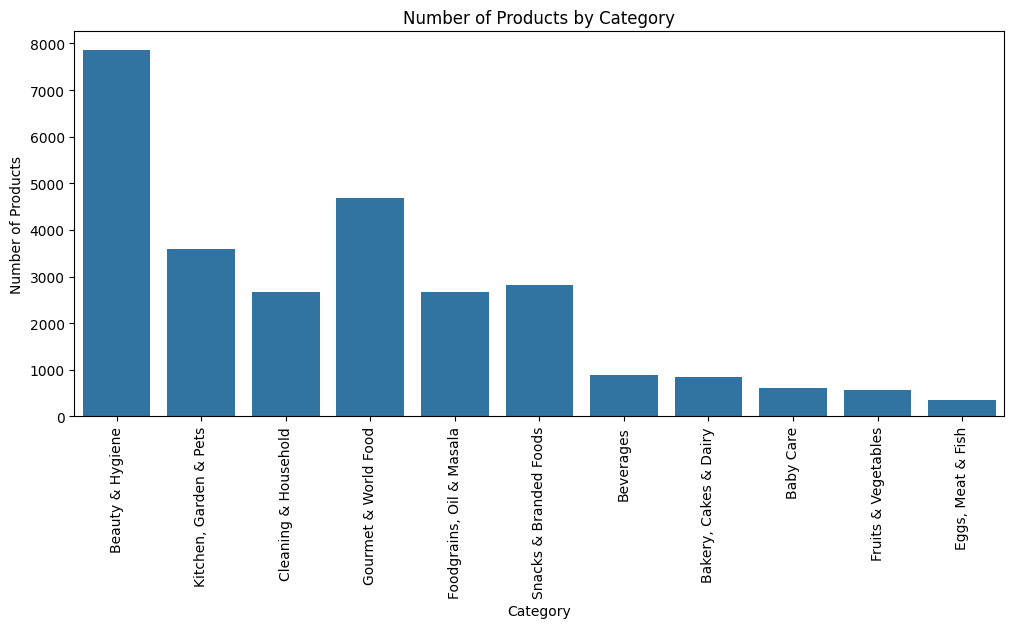

In [45]:
#bar plot for number of products by category

plt.figure(figsize=(12, 5))

sns.countplot(data=data, x="category")

plt.title("Number of Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=90)
plt.show()


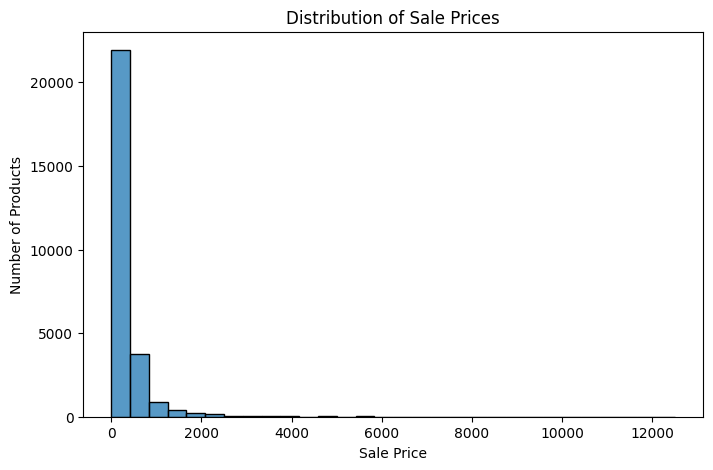

In [46]:
#histogram showing sale price prediction

plt.figure(figsize=(8, 5))

sns.histplot(data=data, x="sale_price", bins=30)

plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Products")
plt.show()


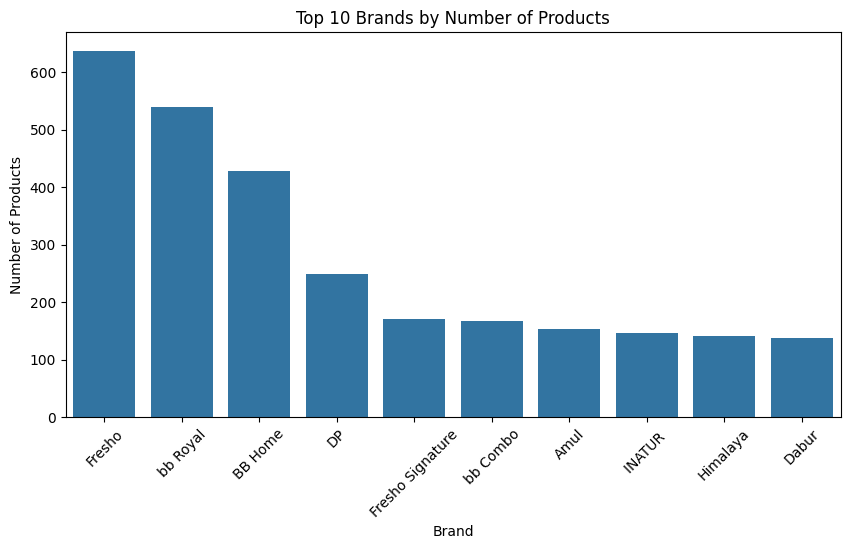

In [47]:
#bar plot showing top 10 brands
top_brands = data["brand"].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(x=top_brands.index, y=top_brands.values)

plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.show()


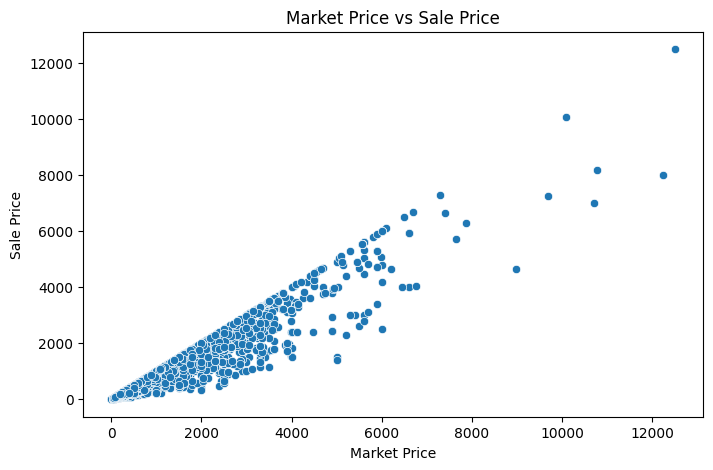

In [48]:
#scatter plot showing relationship between market price and sale price
plt.figure(figsize=(8, 5))

sns.scatterplot(data=data, x="market_price", y="sale_price")

plt.title("Market Price vs Sale Price")
plt.xlabel("Market Price")
plt.ylabel("Sale Price")
plt.show()


# **Data Cleaing**

In [49]:
#check for duplicates
print(data.duplicated().sum())

0


In [50]:
# Create a copy for cleaning
cleaned_data = data.copy()

In [51]:
#Handle missing values
cleaned_data.dropna(subset=["product"], inplace=True)
cleaned_data["brand"] = cleaned_data["brand"].fillna("Unknown")
cleaned_data["description"]=cleaned_data["description"].fillna("Not Available")
# Kept missing ratings as they do not affect the other product information.

In [52]:
# Remove unnecessary spaces from brand names
cleaned_data["brand"] = cleaned_data["brand"].str.strip()
cleaned_data["description"] = cleaned_data["description"].str.strip()

In [53]:
#Rename columns
cleaned_data.rename(columns={
    "product": "product_name",
    "type": "product_type"
    }, inplace=True)
print(cleaned_data.columns)

Index(['index', 'product_name', 'category', 'sub_category', 'brand',
       'sale_price', 'market_price', 'product_type', 'rating', 'description'],
      dtype='object')


In [54]:
#Saved cleaned data to CSV.
cleaned_data.to_csv("BigBasket_Cleaned.csv", index=False)

# **Dashbourd**

In [55]:
%%writefile app.py
from pathlib import Path

import pandas as pd
import streamlit as st

st.set_page_config(page_title="BigBasket Dashboard", layout="wide")

GREEN = "#78A927"
RED = "#DE4739"
YELLOW = "#FFE36E"
CREAM = "#FFF9E8"

folder = Path(__file__).resolve().parent
raw_file = folder / "BigBasket Products.csv"
clean_file = folder / "BigBasket_Cleaned.csv"


def load_catalog(file):
    catalog = pd.read_csv(file)
    catalog = catalog.rename(columns={"product": "product_name"})

    # Convert text prices such as "₹1,200" to numbers before filtering.
    for column in ["sale_price", "market_price", "rating"]:
        text = catalog[column].astype("string").str.strip()
        text = text.str.replace("₹", "", regex=False)
        text = text.str.replace(",", "", regex=False)
        catalog[column] = pd.to_numeric(text, errors="coerce")

    return catalog


st.markdown(
    f"""
    <style>
    .stApp {{ background: {CREAM}; }}
    [data-testid="stSidebar"] {{ background: #ECF6C9; }}
    [data-testid="stMetric"] {{
        background: white;
        color: #20351B;
        border-top: 5px solid {GREEN};
        border-radius: 12px;
        padding: 14px;
    }}
    .basket-banner {{
        background: {YELLOW};
        border-left: 10px solid {RED};
        border-radius: 16px;
        padding: 20px 24px;
        margin-bottom: 16px;
    }}
    .basket-banner h1, .basket-banner p {{
        color: #20351B;
        margin: 0;
        padding: 0;
    }}
    </style>

    <div class="basket-banner">
        <h1>BigBasket Product Catalog</h1>
        <p>Compare prices, discounts, and ratings across supermarket categories.</p>
    </div>
    """,
    unsafe_allow_html=True,
)

for file in [raw_file, clean_file]:
    if not file.exists():
        st.error(f"Place {file.name} in the same folder as app.py.")
        st.stop()

before = load_catalog(raw_file)
after = load_catalog(clean_file)

st.sidebar.header("Catalog filters")
categories = sorted(before["category"].dropna().unique())
category = st.sidebar.selectbox("Category", ["All categories", *categories])

use_budget = st.sidebar.checkbox("Set a maximum price")
budget = st.sidebar.number_input(
    "Maximum sale price (₹)",
    min_value=0.0,
    value=500.0,
    step=10.0,
    disabled=not use_budget,
)

view = st.radio(
    "Dashboard view",
    ["Before cleaning", "After cleaning", "Cleaning impact"],
    horizontal=True,
)

if view == "Cleaning impact":
    st.subheader("What changed across the full catalog?")
    st.caption("These counts cover the full dataset, regardless of the sidebar filters.")

    left, middle, right = st.columns(3)
    left.metric("Before cleaning", f"{len(before):,}")
    middle.metric("After cleaning", f"{len(after):,}")
    right.metric("Listings removed", f"{len(before) - len(after):,}")

    fields = ["product_name", "brand", "description", "rating"]
    missing = pd.DataFrame({
        "Before": before[fields].isna().sum(),
        "After": after[fields].isna().sum(),
    })
    missing.index = ["Product name", "Brand", "Description", "Rating"]

    st.bar_chart(missing, color=[RED, GREEN])
    st.dataframe(missing)
    st.caption(
        "The cleaning step removes listings with no product name and labels missing "
        "brands and descriptions. Missing ratings stay blank."
    )
    st.stop()

catalog = before if view == "Before cleaning" else after

if category != "All categories":
    catalog = catalog[catalog["category"] == category]

if use_budget:
    catalog = catalog[catalog["sale_price"] <= budget]

if catalog.empty:
    st.info("No listings match your filters. Try a higher budget or another category.")
    st.stop()

products = catalog.copy()
market_price = products["market_price"].where(products["market_price"] > 0)
products["Discount (%)"] = (
    (market_price - products["sale_price"]) / market_price * 100
).round(1)

discounted = products["sale_price"] < market_price
rated = products["rating"].count()
median_price = products["sale_price"].median()
average_rating = products["rating"].mean()

a, b, c, d = st.columns(4)
a.metric("Listings", f"{len(products):,}")
b.metric("Median sale price", f"₹{median_price:,.2f}" if pd.notna(median_price) else "—")
c.metric("Discounted listings", f"{discounted.sum():,}")
d.metric("Average rating", f"{average_rating:.2f} / 5" if rated else "—")
st.caption(f"Average rating uses {rated:,} of {len(products):,} listings.")

st.subheader("Listings and discounts by category")
chart = products.groupby("category").size().rename("All listings").to_frame()
chart["Discounted listings"] = (
    products.loc[discounted].groupby("category").size()
    .reindex(chart.index, fill_value=0)
)
st.bar_chart(chart, color=[GREEN, RED])

st.subheader("Product listings")
columns = [
    "product_name", "brand", "category",
    "sale_price", "market_price", "Discount (%)", "rating",
]
table = products[columns].rename(columns={
    "product_name": "Product",
    "brand": "Brand",
    "category": "Category",
    "sale_price": "Sale price (₹)",
    "market_price": "Market price (₹)",
    "rating": "Rating",
})
st.dataframe(table, hide_index=True)

Overwriting app.py
